# Lista de Exercícios: Aprendizado Não Supervisionado
**Disciplina:** Inteligência Artificial  
**Instituição:** Fatec Mogi Mirim / Centro Paula Souza  

---

### Instruções Gerais:
1. Execute a célula abaixo para instalar/importar as bibliotecas necessárias.
2. Responda a cada exercício preenchendo o código indicado nas seções `# SEU CÓDIGO AQUI`.
3. Analise e comente as saídas geradas quando solicitado.

In [8]:
# Instalação das dependências necessárias (descomente caso necessário)
# !pip install pandas numpy matplotlib seaborn scikit-learn scipy mlxtend

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.datasets import load_iris
from scipy.cluster.hierarchy import linkage, dendrogram

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---
## Exercício 1: K-Means no Dataset Titanic
**Objetivo:** Agrupar os passageiros do Titanic em 3 clusters com base em sua Idade (`Age`), Classe da Passagem (`Pclass`) e Tarifa (`Fare`).

**Instruções:**
1. Carregue o dataset do Titanic usando o Seaborn (`sns.load_dataset('titanic')`).
2. Trate os dados ausentes na coluna `age` (preenchendo com a média/mediana).
3. Selecione as colunas relevantes (`pclass`, `age`, `fare`).
4. Padronize as features numéricas (`age`, `fare`) usando `StandardScaler`.
5. Execute o algoritmo K-Means com $n\_clusters = 3$.
6. Adicione a coluna de clusters ao DataFrame e analise a distribuição dos passageiros nos clusters.

In [9]:
# 1. Carregar dataset do Titanic via Seaborn
titanic = sns.load_dataset('titanic')
df = titanic.copy()

# 2. Tratar dados ausentes na coluna 'age' com a média
df['age'] = df['age'].fillna(df['age'].mean())

# 3. Selecionar as colunas relevantes (pclass, age, fare)
colunas_relevantes = ['pclass', 'age', 'fare']
X = df[colunas_relevantes].copy()

# 4. Padronizar as features numéricas ('age' e 'fare') usando StandardScaler
scaler = StandardScaler()
X[['age', 'fare']] = scaler.fit_transform(X[['age', 'fare']])

# 5. Executar o K-Means com n_clusters=3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster_KMeans'] = kmeans.fit_predict(X)

# 6. Analisar a distribuição dos passageiros nos clusters
print("Distribuição dos passageiros por cluster (K-Means):")
print(df['Cluster_KMeans'].value_counts())
print("\nMédias das variáveis por cluster:")
display(df.groupby('Cluster_KMeans')[['pclass', 'age', 'fare', 'survived']].mean())

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Distribuição dos passageiros por cluster (K-Means):
Cluster_KMeans
0    603
1    253
2     35
Name: count, dtype: int64

Médias das variáveis por cluster:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,pclass,age,fare,survived
Cluster_KMeans,,,,
0,2.794362,25.025738,15.237471,0.301824
1,1.332016,40.986866,46.441321,0.533597
2,1.000000,28.620471,221.602857,0.714286


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

---
## Exercício 2: Clusterização Hierárquica no Dataset Titanic
**Objetivo:** Aplicar a Clusterização Hierárquica nos mesmos dados do Exercício 1 e visualizar o resultado com um dendrograma.

**Instruções:**
1. Utilize os mesmos dados pré-processados do Exercício 1.
2. Calcule a matriz de ligação usando `linkage()` do `scipy.cluster.hierarchy`.
3. Plote o dendrograma para visualizar a hierarquia dos clusters.
4. Aplique o `AgglomerativeClustering` com $n\_clusters = 3$ e adicione a coluna de clusters ao DataFrame.

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

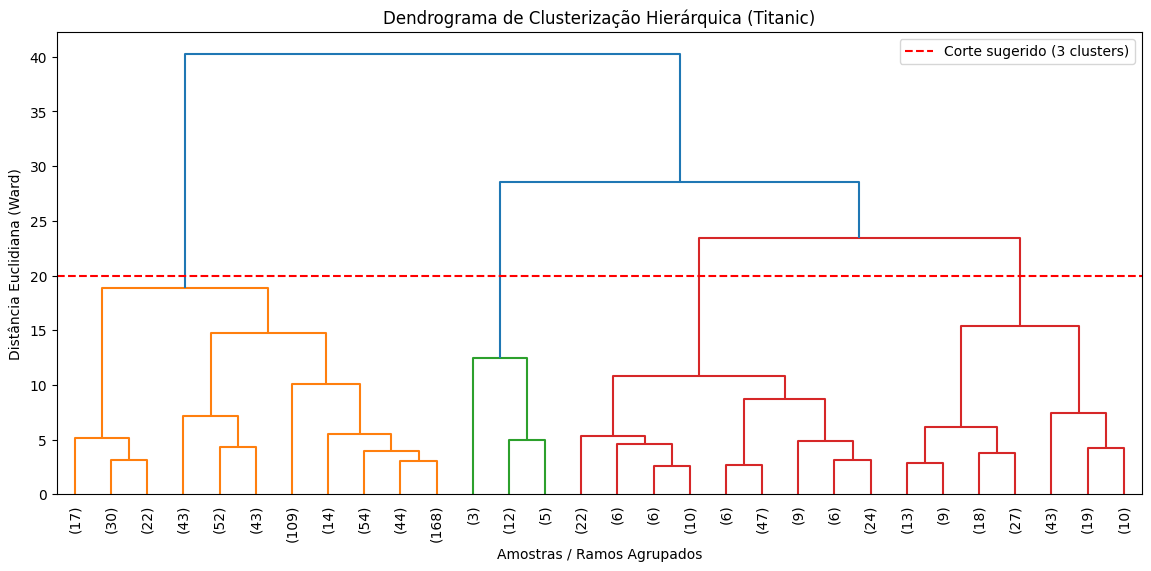

Distribuição dos passageiros por cluster (Hierárquico):
Cluster_Hierarquico
1    596
0    275
2     20
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [10]:
# 1. Utilizar os mesmos dados pré-processados (X) do Exercício 1
X_hierarquico = X.copy()

# 2. Calcular a matriz de ligação usando método Ward
Z = linkage(X_hierarquico, method='ward')

# 3. Plotar o dendrograma
plt.figure(figsize=(14, 6))
# truncate_mode='lastp' resume a exibição em 30 ramos principais para manter o gráfico legível
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=10)
plt.title('Dendrograma de Clusterização Hierárquica (Titanic)')
plt.xlabel('Amostras / Ramos Agrupados')
plt.ylabel('Distância Euclidiana (Ward)')
plt.axhline(y=20, color='r', linestyle='--', label='Corte sugerido (3 clusters)')
plt.legend()
plt.show()

# 4. Aplicar AgglomerativeClustering com n_clusters=3
hierarchical = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
df['Cluster_Hierarquico'] = hierarchical.fit_predict(X_hierarquico)

print("Distribuição dos passageiros por cluster (Hierárquico):")
print(df['Cluster_Hierarquico'].value_counts())

---
## Exercício 3: K-Means e Clusterização Hierárquica no Dataset Iris
**Objetivo:** Aplicar ambos os algoritmos no dataset Iris, que é simples e ideal para visualização.

**Instruções:**
1. Carregue o dataset Iris (`load_iris` do `sklearn.datasets`).
2. Execute o K-Means com $n\_clusters=3$.
3. Plote os resultados do K-Means em um gráfico de dispersão 2D.
4. Execute a Clusterização Hierárquica e plote o dendrograma.
5. Compare os resultados dos dois algoritmos.

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

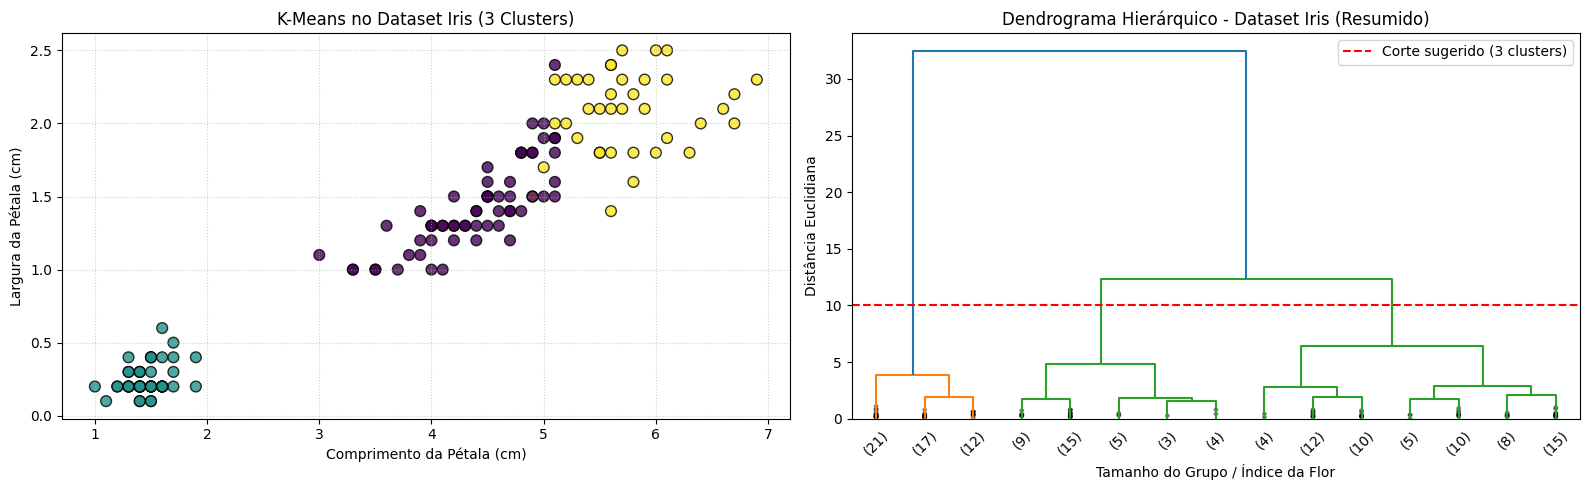

Tabela Cruzada: K-Means vs Clusterização Hierárquica:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Hierárquico,0,1,2
K-Means,,,
0,62,0,0
1,0,50,0
2,2,0,36


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [14]:
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt
import pandas as pd

# 1. Carregar dataset Iris
iris = load_iris(as_frame=True)
X_iris = iris.data.copy()
df_iris = X_iris.copy()
df_iris['especie_real'] = iris.target

# 2. Executar K-Means (n_clusters=3)
kmeans_iris = KMeans(n_clusters=3, random_state=42, n_init=10)
df_iris['Cluster_KMeans'] = kmeans_iris.fit_predict(X_iris)

# 3 e 4. Visualizações lado a lado (Dispersão K-Means + Dendrograma Limpo)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Gráfico 1: Dispersão 2D do K-Means
scatter = ax1.scatter(
    df_iris['petal length (cm)'],
    df_iris['petal width (cm)'],
    c=df_iris['Cluster_KMeans'],
    cmap='viridis',
    s=60,
    alpha=0.8,
    edgecolors='k'
)
ax1.set_title('K-Means no Dataset Iris (3 Clusters)')
ax1.set_xlabel('Comprimento da Pétala (cm)')
ax1.set_ylabel('Largura da Pétala (cm)')
ax1.grid(True, linestyle=':', alpha=0.6)

# Gráfico 2: Dendrograma Hierárquico Resumido e Legível
Z_iris = linkage(X_iris, method='ward')
dendrogram(
    Z_iris,
    truncate_mode='lastp',
    p=15,
    leaf_rotation=45,
    leaf_font_size=10,
    show_contracted=True,
    ax=ax2
)
ax2.set_title('Dendrograma Hierárquico - Dataset Iris (Resumido)')
ax2.set_xlabel('Tamanho do Grupo / Índice da Flor')
ax2.set_ylabel('Distância Euclidiana')
ax2.axhline(y=10, color='r', linestyle='--', label='Corte sugerido (3 clusters)')
ax2.legend()

plt.tight_layout()
plt.show()

# 4b. Treinar AgglomerativeClustering (n_clusters=3)
agg_iris = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
df_iris['Cluster_Hierarquico'] = agg_iris.fit_predict(X_iris)

# 5. Comparação e observações
print("Tabela Cruzada: K-Means vs Clusterização Hierárquica:")
crosstab = pd.crosstab(
    df_iris['Cluster_KMeans'],
    df_iris['Cluster_Hierarquico'],
    rownames=['K-Means'],
    colnames=['Hierárquico']
)
display(crosstab)

---
## Exercício 4: Análise de Cesta de Compras Básica
**Objetivo:** Dado o conjunto de transações abaixo, utilize o algoritmo Apriori para encontrar regras de associação que tenham um **suporte mínimo de 0.5** e uma **confiança mínima de 0.7**.

**Dados de entrada:**
```python
dataset = [
    ['Pão', 'Leite'],
    ['Pão', 'Fralda', 'Cerveja', 'Ovos'],
    ['Leite', 'Fralda', 'Cerveja', 'Coca-cola'],
    ['Pão', 'Leite', 'Fralda', 'Cerveja'],
    ['Pão', 'Leite', 'Fralda', 'Coca-cola']
]
```

**Instruções:**
1. Transformar a lista de transações em um DataFrame booleano usando `TransactionEncoder`.
2. Gerar os frequent itemsets com suporte 0.5.
3. Gerar as regras de associação e filtrar pelo valor de confiança (>= 0.7).
4. Exibir as colunas `antecedents`, `consequents`, `support`, `confidence` e `lift`.

In [12]:
dataset_ex4 = [
    ['Pão', 'Leite'],
    ['Pão', 'Fralda', 'Cerveja', 'Ovos'],
    ['Leite', 'Fralda', 'Cerveja', 'Coca-cola'],
    ['Pão', 'Leite', 'Fralda', 'Cerveja'],
    ['Pão', 'Leite', 'Fralda', 'Coca-cola']
]

# 1. Transformar em DataFrame Booleano usando TransactionEncoder
te = TransactionEncoder()
te_ary = te.fit(dataset_ex4).transform(dataset_ex4)
df_onehot4 = pd.DataFrame(te_ary, columns=te.columns_)

# 2. Gerar itemsets frequentes com suporte mínimo de 0.5 (50%)
frequent_itemsets4 = apriori(df_onehot4, min_support=0.5, use_colnames=True)
print("Itemsets Frequentes (Suporte >= 0.5):")
display(frequent_itemsets4)

# 3. Gerar regras de associação com confiança mínima de 0.7 (70%)
regras4 = association_rules(frequent_itemsets4, metric="confidence", min_threshold=0.7)

# 4. Exibir as colunas solicitadas
resultado_ex4 = regras4[['antecedents', 'consequents', 'support', 'confidence', 'lift']]
print("\nRegras de Associação Filtradas (Confiança >= 0.7):")
display(resultado_ex4)

Itemsets Frequentes (Suporte >= 0.5):


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,support,itemsets
0,0.6,(Cerveja)
1,0.8,(Fralda)
2,0.8,(Leite)
3,0.8,(Pão)
4,0.6,"(Cerveja, Fralda)"
5,0.6,"(Leite, Fralda)"
6,0.6,"(Fralda, Pão)"
7,0.6,"(Leite, Pão)"


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


Regras de Associação Filtradas (Confiança >= 0.7):


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,antecedents,consequents,support,confidence,lift
0,(Cerveja),(Fralda),0.6,1.00,1.2500
1,(Fralda),(Cerveja),0.6,0.75,1.2500
2,(Leite),(Fralda),0.6,0.75,0.9375
3,(Fralda),(Leite),0.6,0.75,0.9375
4,(Fralda),(Pão),0.6,0.75,0.9375
5,(Pão),(Fralda),0.6,0.75,0.9375
6,(Leite),(Pão),0.6,0.75,0.9375
7,(Pão),(Leite),0.6,0.75,0.9375


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

---
## Exercício 5: Otimização de Estoque com Filtros Avançados
**Objetivo:** Crie um script que processe as transações abaixo e retorne apenas as regras que atendam aos seguintes critérios:
- **Lift superior a 1.2**
- **Confiança superior a 0.8**

**Dados de entrada:**
```python
vendas = [
    ['Smartphone', 'Capa', 'Película'],
    ['Smartphone', 'Fone de Ouvido'],
    ['Capa', 'Película'],
    ['Smartphone', 'Capa', 'Película', 'Fone de Ouvido'],
    ['Carregador', 'Smartphone'],
    ['Capa', 'Película', 'Carregador']
]
```

**Instruções:**
1. Processar os dados para o formato aceito pelo `mlxtend`.
2. Calcular o suporte de cada itemset.
3. Gerar as regras e aplicar o filtro duplo (Confiança > 0.8 e Lift > 1.2).
4. **Desafio Extra:** Ordene o resultado final pelo Lift de forma decrescente.

In [13]:
vendas_ex5 = [
    ['Smartphone', 'Capa', 'Película'],
    ['Smartphone', 'Fone de Ouvido'],
    ['Capa', 'Película'],
    ['Smartphone', 'Capa', 'Película', 'Fone de Ouvido'],
    ['Carregador', 'Smartphone'],
    ['Capa', 'Película', 'Carregador']
]

# 1. Processar dados com TransactionEncoder
te5 = TransactionEncoder()
te_ary5 = te5.fit(vendas_ex5).transform(vendas_ex5)
df_onehot5 = pd.DataFrame(te_ary5, columns=te5.columns_)

# 2. Calcular suporte dos itemsets (usando suporte mínimo de 0.2 para capturar todas as regras relevantes)
frequent_itemsets5 = apriori(df_onehot5, min_support=0.2, use_colnames=True)

# 3. Gerar regras e aplicar filtro duplo: Confiança > 0.8 e Lift > 1.2
regras5 = association_rules(frequent_itemsets5, metric="confidence", min_threshold=0.8)
regras_filtradas = regras5[regras5['lift'] > 1.2]

# 4. Ordenar resultado final pelo Lift em ordem decrescente
resultado_ex5 = regras_filtradas[['antecedents', 'consequents', 'support', 'confidence', 'lift']].sort_values(by='lift', ascending=False)

print("Regras com Lift > 1.2 e Confiança > 0.8 (Ordenadas por Lift):")
display(resultado_ex5)

Regras com Lift > 1.2 e Confiança > 0.8 (Ordenadas por Lift):


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,antecedents,consequents,support,confidence,lift
0,(Capa),(Película),0.666667,1.0,1.5
1,(Película),(Capa),0.666667,1.0,1.5
2,(Fone de Ouvido),(Smartphone),0.333333,1.0,1.5
3,"(Smartphone, Capa)",(Película),0.333333,1.0,1.5
4,"(Smartphone, Película)",(Capa),0.333333,1.0,1.5


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag